# Why Do Patients Miss Medical Appointments?

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Business question:** About one in five medical appointments in this dataset is missed. Which patient and scheduling factors are associated with no-shows, and can missed appointments be predicted well enough to target reminders?

**Data:** 110,527 public appointment records from clinics in Vitória, Brazil (2016), from Kaggle's *Medical Appointment No Shows* dataset.

**Approach**
1. Inspect and clean the data
2. Engineer scheduling features such as lead time
3. Explore six descriptive views of attendance
4. Test which differences are statistically significant
5. Check for confounding (the SMS reminder paradox)
6. Build and evaluate a predictive model against a baseline

The analysis is descriptive and predictive, **not causal**, and is not a clinical tool.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, RocCurveDisplay

import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
TEAL, BLUE, ORANGE = "#0f766e", "#365bd6", "#c2410c"

df = pd.read_csv("../data/KaggleV2-May-2016.csv")
print(df.shape)
df.head(3)

(110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No


## 1. Inspect and clean

In [2]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Negative ages: ", int((df["Age"] < 0).sum()))

df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"]).dt.tz_localize(None)
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"]).dt.tz_localize(None)
df["LeadDays"] = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days
print("Appointments booked after the appointment date:", int((df["LeadDays"] < 0).sum()))

Missing values: 0
Duplicate rows: 0
Negative ages:  1
Appointments booked after the appointment date: 5


In [3]:
clean = df[(df["Age"] >= 0) & (df["LeadDays"] >= 0)].copy()
clean["Missed"] = (clean["No-show"] == "Yes").astype(int)
clean["Weekday"] = clean["AppointmentDay"].dt.day_name()
clean["AgeGroup"] = pd.cut(clean["Age"], [-1, 12, 18, 35, 50, 65, 120],
                           labels=["0-12", "13-18", "19-35", "36-50", "51-65", "65+"])
clean["LeadBand"] = pd.cut(clean["LeadDays"], [-1, 0, 7, 30, 1000],
                           labels=["Same day", "1-7 days", "8-30 days", "30+ days"])
print(f"Rows: {len(df):,} -> {len(clean):,} after removing invalid ages and dates")
print(f"Overall no-show rate: {clean['Missed'].mean():.2%}")

Rows: 110,527 -> 110,521 after removing invalid ages and dates
Overall no-show rate: 20.19%


## 2. Six descriptive views

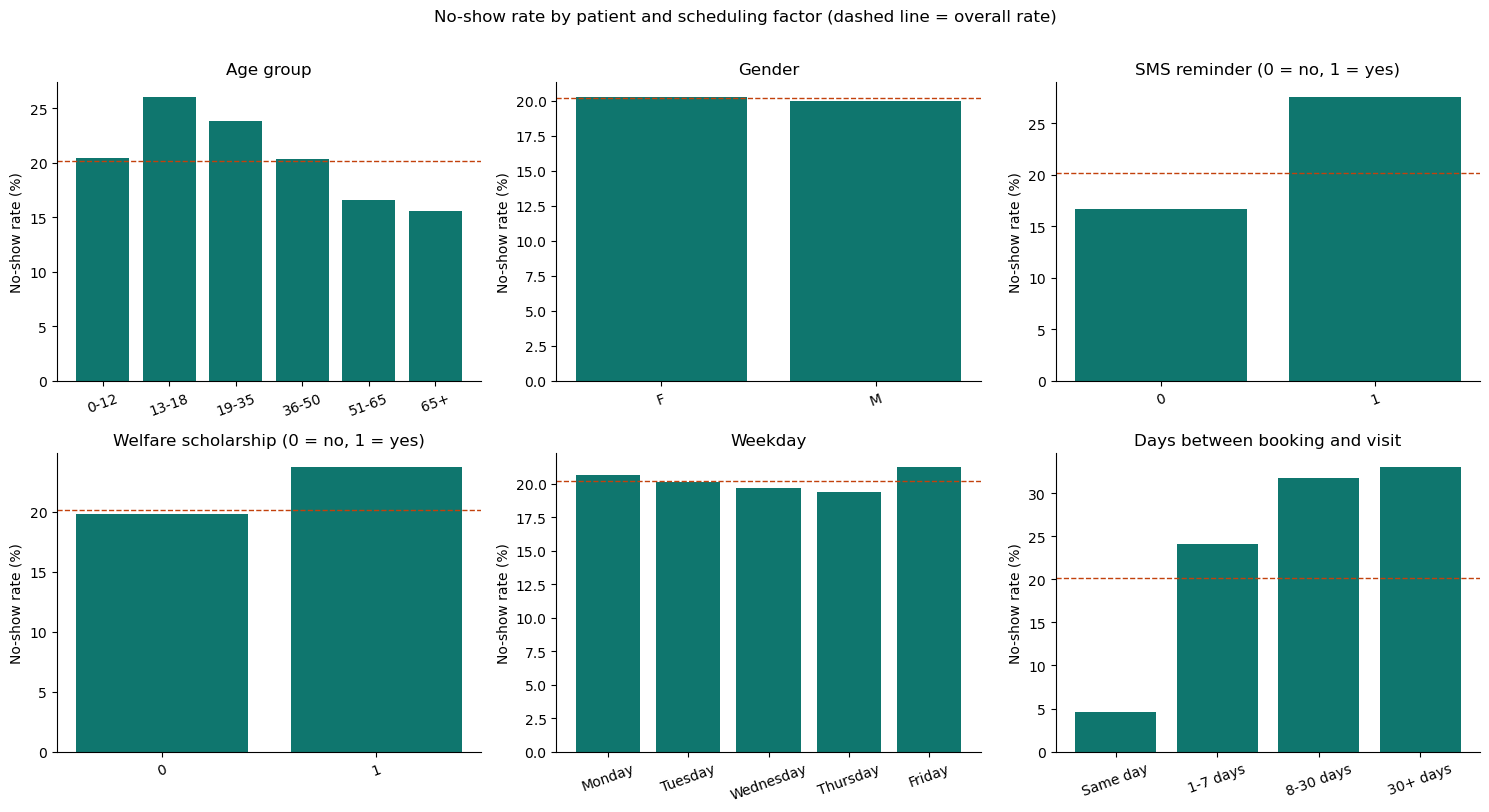

In [4]:
def rate(col, order=None):
    r = clean.groupby(col, observed=True)["Missed"].mean().mul(100)
    return r.reindex(order) if order else r

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
views = [
    ("AgeGroup", None, "Age group"),
    ("Gender", None, "Gender"),
    ("SMS_received", None, "SMS reminder (0 = no, 1 = yes)"),
    ("Scholarship", None, "Welfare scholarship (0 = no, 1 = yes)"),
    ("Weekday", ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"], "Weekday"),
    ("LeadBand", None, "Days between booking and visit"),
]
for ax, (col, order, title) in zip(axes.flat, views):
    r = rate(col, order)
    ax.bar(r.index.astype(str), r.values, color=TEAL)
    ax.axhline(clean["Missed"].mean() * 100, color=ORANGE, ls="--", lw=1)
    ax.set_title(title); ax.set_ylabel("No-show rate (%)"); ax.tick_params(axis="x", rotation=20)
fig.suptitle("No-show rate by patient and scheduling factor (dashed line = overall rate)", y=1.01)
plt.tight_layout(); plt.savefig("../images/no_show_rates_by_factor.png", dpi=150, bbox_inches="tight"); plt.show()

In [5]:
pd.DataFrame({"no-show rate %": rate("LeadBand").round(1),
              "appointments": clean["LeadBand"].value_counts().reindex(rate("LeadBand").index)})

,no-show rate %,appointments
LeadBand,,
Same day,4.6,38562
1-7 days,24.1,32185
8-30 days,31.7,29396
30+ days,33.0,10378


**Lead time is the strongest pattern:** same-day appointments are almost always kept, while appointments booked more than a month ahead are missed far more often.

## 3. Which differences are statistically significant?
Chi-square tests of independence (categorical factors) and a Mann-Whitney U test (age). With 110,000 rows, even small differences can be significant, so the **effect size** (difference in no-show rate) matters as much as the p-value.

In [6]:
rows = []
for col in ["Gender", "SMS_received", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Weekday", "AgeGroup", "LeadBand"]:
    table = pd.crosstab(clean[col], clean["Missed"])
    chi2, p, dof, _ = chi2_contingency(table)
    r = rate(col)
    rows.append({"factor": col, "chi²": round(chi2, 1), "p-value": f"{p:.1e}",
                 "lowest rate %": round(r.min(), 1), "highest rate %": round(r.max(), 1),
                 "gap (pts)": round(r.max() - r.min(), 1)})
u, p_age = mannwhitneyu(clean.loc[clean.Missed == 1, "Age"], clean.loc[clean.Missed == 0, "Age"])
print(f"Age (Mann-Whitney U): median age kept {clean.loc[clean.Missed==0,'Age'].median():.0f} vs "
      f"missed {clean.loc[clean.Missed==1,'Age'].median():.0f}, p = {p_age:.1e}")
pd.DataFrame(rows).sort_values("gap (pts)", ascending=False).reset_index(drop=True)

Age (Mann-Whitney U): median age kept 38 vs missed 33, p = 4.3e-92


,factor,chi²,p-value,lowest rate %,highest rate %,gap (pts)
0,LeadBand,9577.7,0.0e+00,4.6,33.0,28.4
1,SMS_received,1768.0,0.0e+00,16.7,27.6,10.9
2,AgeGroup,728.1,4.0e-155,15.5,26.1,10.5
3,Scholarship,93.8,3.5e-22,19.8,23.7,3.9
4,Weekday,27.6,4.4e-05,19.3,23.1,3.7
5,Hipertension,140.3,2.2e-32,17.3,20.9,3.6
6,Diabetes,25.2,5.0e-07,18.0,20.4,2.4
7,Gender,1.9,1.7e-01,20.0,20.3,0.3
8,Alcoholism,0.0,9.7e-01,20.1,20.2,0.0


## 4. The SMS reminder paradox
At first glance, patients who **received** an SMS reminder missed *more* appointments. That does not mean reminders cause no-shows: reminders are only sent for appointments booked days in advance, and those already carry a higher no-show risk. Comparing within the same lead-time band tells the real story.

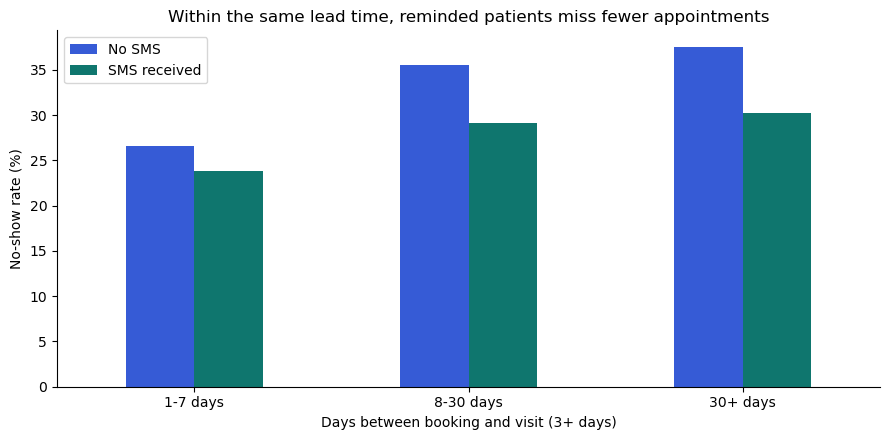

Overall rates: {0: 16.7, 1: 27.6}


,No SMS,SMS received
LeadBand,,
1-7 days,26.6,23.8
8-30 days,35.6,29.1
30+ days,37.5,30.2


In [7]:
sms = (clean[clean["LeadDays"] >= 3]
       .groupby(["LeadBand", "SMS_received"], observed=True)["Missed"].mean().mul(100).unstack().round(1))
sms.columns = ["No SMS", "SMS received"]
ax = sms.plot.bar(color=[BLUE, TEAL], rot=0, figsize=(9, 4.5))
ax.set(title="Within the same lead time, reminded patients miss fewer appointments",
       ylabel="No-show rate (%)", xlabel="Days between booking and visit (3+ days)")
plt.tight_layout(); plt.savefig("../images/sms_paradox.png", dpi=150, bbox_inches="tight"); plt.show()
print("Overall rates:", rate("SMS_received").round(1).to_dict())
sms

This is a classic case of confounding (related to Simpson's paradox). Within comparable appointments, the reminder is associated with **lower** no-show rates.

## 5. Can no-shows be predicted?
Because only ~20% of appointments are missed, a model that always predicts *attended* already scores ~80% accuracy. Accuracy is therefore a poor metric here; **ROC-AUC** and **recall** of missed appointments are what matter for targeting reminders.

In [8]:
features = ["Age", "Gender", "Scholarship", "Hipertension", "Diabetes", "Alcoholism", "Handcap",
            "SMS_received", "LeadDays", "Weekday"]
X = clean[features].copy()
X["ScheduledHour"] = clean["ScheduledDay"].dt.hour
y = clean["Missed"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

cat = ["Gender", "Weekday"]
num = [c for c in X.columns if c not in cat]
prep = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
models = {
    "Baseline (always 'attended')": make_pipeline(prep, DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_pipeline(prep, LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Gradient boosting": make_pipeline(prep, HistGradientBoostingClassifier(random_state=SEED, class_weight="balanced")),
}
cv = {}
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=5, scoring=["roc_auc", "accuracy", "recall"])
    cv[name] = {"CV ROC-AUC": s["test_roc_auc"].mean(), "CV accuracy": s["test_accuracy"].mean(),
                "CV recall (missed)": s["test_recall"].mean()}
pd.DataFrame(cv).T.round(3)

,CV ROC-AUC,CV accuracy,CV recall (missed)
Baseline (always 'attended'),0.500,0.798,0.000
Logistic regression,0.669,0.665,0.571
Gradient boosting,0.735,0.591,0.822


Test ROC-AUC: 0.729
Test recall (missed appointments caught): 0.827 | precision: 0.307
No-show rate among the 20% of appointments the model rates riskiest: 37.4% (vs 20.2% overall, 1.9x lift)


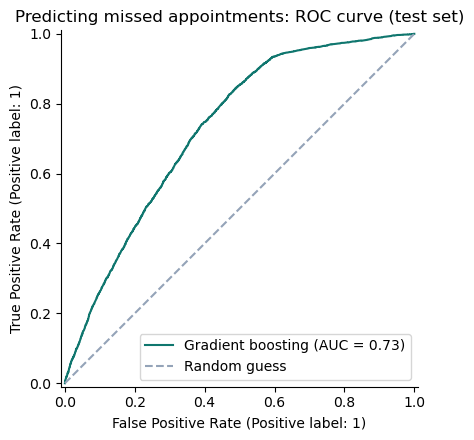

In [9]:
best = models["Gradient boosting"].fit(X_train, y_train)
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print(f"Test ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
print(f"Test recall (missed appointments caught): {recall_score(y_test, pred):.3f} | precision: {precision_score(y_test, pred):.3f}")

top20 = y_test[proba >= np.quantile(proba, 0.8)].mean()
print(f"No-show rate among the 20% of appointments the model rates riskiest: {top20:.1%} "
      f"(vs {y_test.mean():.1%} overall, {top20 / y_test.mean():.1f}x lift)")

RocCurveDisplay.from_predictions(y_test, proba, name="Gradient boosting", color=TEAL)
plt.plot([0, 1], [0, 1], "--", color="#94a3b8", label="Random guess"); plt.legend()
plt.title("Predicting missed appointments: ROC curve (test set)")
plt.tight_layout(); plt.savefig("../images/roc_curve.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Findings and recommendations
- **Lead time is the strongest driver.** Same-day appointments are rarely missed; long waits sharply increase no-shows. *Recommendation:* offer shorter booking windows or confirmation calls for appointments booked weeks ahead.
- **SMS reminders appear helpful once lead time is accounted for.** The raw comparison is misleading because reminders go to higher-risk, far-ahead bookings.
- **Younger adults and welfare-scholarship patients** miss more often; age and lead time are significant at any conventional level. **Gender and alcoholism show no meaningful difference**, which rules them out as targeting criteria.
- **Prediction is useful for targeting, not for certainty.** The model ranks appointments by risk well enough to focus reminder calls on the riskiest fifth, where no-show rates are far above average, but it cannot tell with certainty who will miss.

**Limitations.** Data comes from one Brazilian city in 2016, lacks reasons for missing, and repeated visits by the same patient are not modelled. Patterns are associations, not causes.